# Retail Sales Data Analysis

## 01 - Data Understanding

This notebook focuses on understanding the structure,
characteristics, and quality of the retail sales dataset.

### Objectives
- Understand the dataset structure.
- Identify data types.
- Check missing values.
- Check duplicate records.
- Explore basic statistical summaries.

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset

df = pd.read_csv(
    "../data/raw/sample_superstore.csv",
    encoding="cp1252"
)

# Display first 5 rows
display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Dataset Overview

In this section, we will explore the dimensions
and overall structure of the dataset.

In [3]:
# Check dataset dimensions

print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (9994, 21)
Number of Rows: 9994
Number of Columns: 21


In [4]:
# Check dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
# Display all column names

for column in df.columns:
    print(column)

Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Customer Name
Segment
Country
City
State
Postal Code
Region
Product ID
Category
Sub-Category
Product Name
Sales
Quantity
Discount
Profit


## 2. Data Quality Check

In this section, we will identify missing values
and duplicate records in the dataset.

In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

display(missing_values)

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
# Calculate total missing values

print("Total Missing Values:", missing_values.sum())

Total Missing Values: 0


In [8]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


## 3. Statistical Summary

This section explores the statistical characteristics
of numerical variables in the dataset.

In [9]:
# Generate descriptive statistics

numerical_columns = ["Sales", "Quantity", "Discount", "Profit"]

display(df[numerical_columns].describe())

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


## 4. Profit Distribution

Analyze the distribution of profit values,
including negative, zero, and positive profits.

In [10]:
# Count profit categories

negative_profit = (df["Profit"] < 0).sum()
zero_profit = (df["Profit"] == 0).sum()
positive_profit = (df["Profit"] > 0).sum()

print("Negative Profit:", negative_profit)
print("Zero Profit:", zero_profit)
print("Positive Profit:", positive_profit)

Negative Profit: 1871
Zero Profit: 65
Positive Profit: 8058


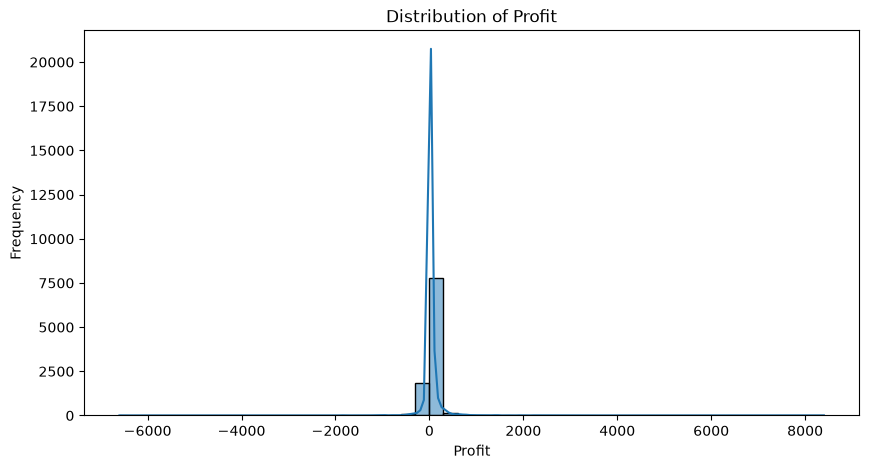

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Profit",
    bins=50,
    kde=True
)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.show()

## 5. Investigating Extreme Profit Values

In this section, we investigate records with
the lowest and highest profit values.

In [12]:
# Display 10 records with the lowest profit

lowest_profit = df.nsmallest(10, "Profit")

display(
    lowest_profit[
        [
            "Order ID",
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Quantity",
            "Discount",
            "Profit"
        ]
    ]
)

,Order ID,Product Name,Category,Sub-Category,Sales,Quantity,Discount,Profit
7772,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,4499.985,5,0.7,-6599.9780
683,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,4,0.5,-3839.9904
9774,CA-2014-169019,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,2177.584,8,0.8,-3701.8928
3011,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,2549.985,5,0.7,-3399.9800
4991,US-2017-122714,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,1889.990,5,0.8,-2929.4845
3151,CA-2015-147830,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,1799.994,2,0.7,-2639.9912
5310,CA-2017-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,1525.188,6,0.8,-2287.7820
9639,CA-2015-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,4297.644,13,0.4,-1862.3124
1199,CA-2016-130946,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,1088.792,4,0.8,-1850.9464
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,6,0.5,-1811.0784


In [13]:
# Display 10 records with the highest profit

highest_profit = df.nlargest(10, "Profit")

display(
    highest_profit[
        [
            "Order ID",
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Quantity",
            "Discount",
            "Profit"
        ]
    ]
)

,Order ID,Product Name,Category,Sub-Category,Sales,Quantity,Discount,Profit
6826,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,17499.950,5,0.0,8399.9760
8153,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,13999.960,4,0.0,6719.9808
4190,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,10499.970,3,0.0,5039.9856
9039,CA-2016-117121,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,9892.740,13,0.0,4946.3700
4098,CA-2014-116904,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,9449.950,5,0.0,4630.4755
2623,CA-2017-127180,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,11199.968,4,0.2,3919.9888
509,CA-2015-145352,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,6354.950,5,0.0,3177.4750
8488,CA-2016-158841,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,8749.950,5,0.0,2799.9840
7666,US-2016-140158,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,5399.910,9,0.0,2591.9568
6520,CA-2017-138289,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,5443.960,4,0.0,2504.2216


## 6. Discount and Profit Analysis

This section explores the relationship between
discount levels and profitability.

The objective is to understand whether higher
discount levels are associated with lower profits.

In [14]:
# Analyze profit based on discount levels

discount_analysis = df.groupby("Discount").agg(
    total_records=("Profit", "count"),
    average_profit=("Profit", "mean"),
    median_profit=("Profit", "median"),
    total_profit=("Profit", "sum"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

discount_analysis["loss_percentage"] = (
    discount_analysis["loss_records"]
    / discount_analysis["total_records"] * 100
)

display(discount_analysis.round(2))

,total_records,average_profit,median_profit,total_profit,loss_records,loss_percentage
Discount,,,,,,
0.00,4798,66.90,16.00,320987.60,0,0.00
0.10,94,96.06,54.32,9029.18,4,4.26
0.15,52,27.29,14.10,1418.99,17,32.69
0.20,3657,24.70,6.49,90337.31,502,13.73
0.30,227,-45.68,-25.38,-10369.28,208,91.63
0.32,27,-88.56,-46.98,-2391.14,27,100.00
0.40,206,-111.93,-57.62,-23057.05,180,87.38
0.45,11,-226.65,-167.32,-2493.11,11,100.00
0.50,66,-310.70,-185.28,-20506.43,66,100.00


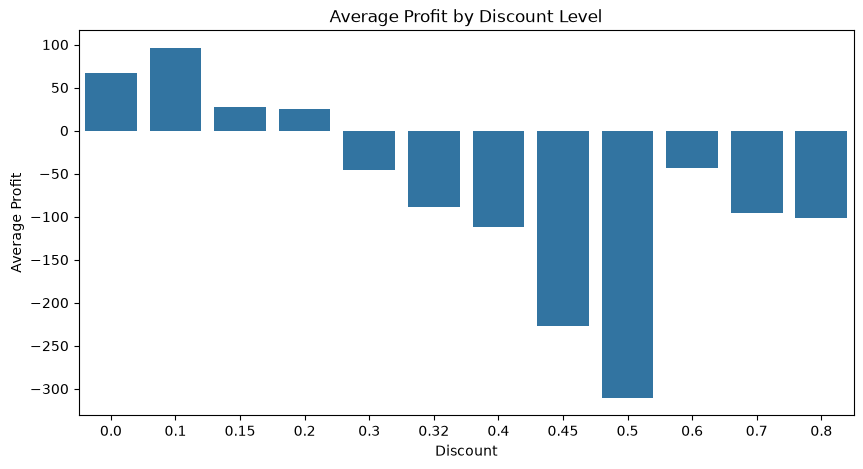

In [15]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Discount",
    y="Profit",
    estimator="mean",
    errorbar=None
)

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")

plt.show()

In [16]:
# Display discount analysis table

display(
    discount_analysis[
        [
            "total_records",
            "average_profit",
            "median_profit",
            "loss_records",
            "loss_percentage"
        ]
    ].sort_index()
)

,total_records,average_profit,median_profit,loss_records,loss_percentage
Discount,,,,,
0.00,4798,66.900292,15.9952,0,0.000000
0.10,94,96.055074,54.3240,4,4.255319
0.15,52,27.288298,14.0980,17,32.692308
0.20,3657,24.702572,6.4944,502,13.727099
0.30,227,-45.679636,-25.3764,208,91.629956
0.32,27,-88.560656,-46.9764,27,100.000000
0.40,206,-111.927429,-57.6242,180,87.378641
0.45,11,-226.646464,-167.3184,11,100.000000
0.50,66,-310.703456,-185.2767,66,100.000000


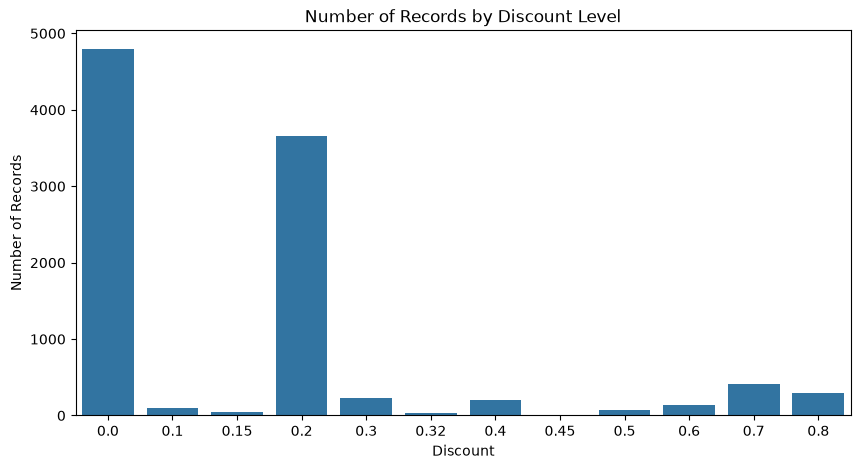

In [17]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Discount"
)

plt.title("Number of Records by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Number of Records")

plt.show()

## 7. Investigating High-Discount Losses

Investigate products with negative profit
at a 50% discount level.

In [18]:
# Filter records with 50% discount and negative profit

discount_05_loss = df[
    (df["Discount"] == 0.5) &
    (df["Profit"] < 0)
].copy()

# Calculate sales value per unit
discount_05_loss["Sales_per_Unit"] = (
    discount_05_loss["Sales"] /
    discount_05_loss["Quantity"]
)

# Display 10 records with the highest sales per unit

display(
    discount_05_loss.nlargest(10, "Sales_per_Unit")[
        [
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Quantity",
            "Sales_per_Unit",
            "Profit"
        ]
    ]
)

,Product Name,Category,Sub-Category,Sales,Quantity,Sales_per_Unit,Profit
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,6,3773.080,-1811.0784
683,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,4,1999.995,-3839.9904
4128,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,2624.985,3,874.995,-944.9946
7646,"3D Systems Cube Printer, 2nd Generation, White",Technology,Machines,1299.990,2,649.995,-571.9956
27,"Riverside Palais Royal Lawyers Bookcase, Royal...",Furniture,Bookcases,3083.430,7,440.490,-1665.0522
1340,Cisco CP-7937G Unified IP Conference Station P...,Technology,Machines,695.700,2,347.850,-27.8280
2838,Cisco CP-7937G Unified IP Conference Station P...,Technology,Machines,695.700,2,347.850,-27.8280
7292,Okidata C610n Printer,Technology,Machines,649.000,2,324.500,-272.5800
2984,"Chromcraft Bull-Nose Wood 48"" x 96"" Rectangula...",Furniture,Tables,275.490,1,275.490,-170.8038
835,Zebra GX420t Direct Thermal/Thermal Transfer P...,Technology,Machines,265.475,1,265.475,-111.4995


## 8. Profit Analysis by Sub-Category

Investigate profitability across different product
sub-categories at a 50% discount level.

The objective is to identify which sub-categories
contribute most to the observed losses.

In [19]:
# Filter records with 50% discount

discount_05 = df[df["Discount"] == 0.5].copy()

# Analyze profit by category and sub-category

subcategory_analysis = discount_05.groupby(
    ["Category", "Sub-Category"]
).agg(
    total_records=("Profit", "count"),
    average_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

subcategory_analysis["loss_percentage"] = (
    subcategory_analysis["loss_records"]
    / subcategory_analysis["total_records"] * 100
)

display(
    subcategory_analysis.sort_values(
        by="average_profit"
    ).round(2)
)

total_records  average_profit  total_profit  \
Category   Sub-Category                                                
Technology Machines                 12         -636.27      -7635.23   
Furniture  Tables                   36         -239.32      -8615.39   
           Bookcases                18         -236.43      -4255.81   

                         loss_records  loss_percentage  
Category   Sub-Category                                 
Technology Machines                12            100.0  
Furniture  Tables                  36            100.0  
           Bookcases               18            100.0

## 9. Comparing Profitability Across Discount Levels

Investigate the profitability of Machines, Tables,
and Bookcases across different discount levels.

The objective is to determine whether their
negative profitability is limited to a specific
discount level or appears across multiple levels.

In [20]:
# Select the sub-categories of interest

target_subcategories = [
    "Machines",
    "Tables",
    "Bookcases"
]

# Filter the dataset

selected_data = df[
    df["Sub-Category"].isin(target_subcategories)
]

# Analyze profitability by sub-category and discount

comparison = selected_data.groupby(
    ["Category", "Sub-Category", "Discount"]
).agg(
    total_records=("Profit", "count"),
    average_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
    loss_records=("Profit", lambda x: (x < 0).sum())
)

comparison["loss_percentage"] = (
    comparison["loss_records"]
    / comparison["total_records"] * 100
)

display(comparison.round(2))

total_records  average_profit  total_profit  \
Category   Sub-Category Discount                                                
Furniture  Bookcases    0.00                 60          101.26       6075.71   
                        0.15                 52           27.29       1418.99   
                        0.20                 46            2.84        130.50   
                        0.30                 10          -55.59       -555.87   
                        0.32                 27          -88.56      -2391.14   
                        0.50                 18         -236.43      -4255.81   
                        0.70                 15         -259.66      -3894.94   
           Tables       0.00                 72          184.39      13276.30   
                        0.20                 71           -4.28       -303.56   
                        0.30                 54          -63.01      -3402.33   
                        0.40                 75         -215.83     -16187.40   
                        0.45                 11         -226.65      -2493.11   
                        0.50                 36         -239.32      -8615.39   
Technology Machines     0.00                 29          935.79      27137.82   
                        0.10                  2          416.04        832.08   
                        0.20                 31          160.33       4970.20   
                        0.30                  5           65.21        326.04   
                        0.40                 13         -205.14      -2666.84   
                        0.50                 12         -636.27      -7635.23   
                        0.70                 23         -851.27     -19579.32   

                                  loss_records  loss_percentage  
Category   Sub-Category Discount                                 
Furniture  Bookcases    0.00                 0             0.00  
                        0.15                17            32.69  
                        0.20                23            50.00  
                        0.30                 9            90.00  
                        0.32                27           100.00  
                        0.50                18           100.00  
                        0.70                15           100.00  
           Tables       0.00                 0             0.00  
                        0.20                31            43.66  
                        0.30                50            92.59  
                        0.40                75           100.00  
                        0.45                11           100.00  
                        0.50                36           100.00  
Technology Machines     0.00                 0             0.00  
                        0.10                 0             0.00  
                        0.20                 0             0.00  
                        0.30                 1            20.00  
                        0.40                 8            61.54  
                        0.50                12           100.00  
                        0.70                23           100.00

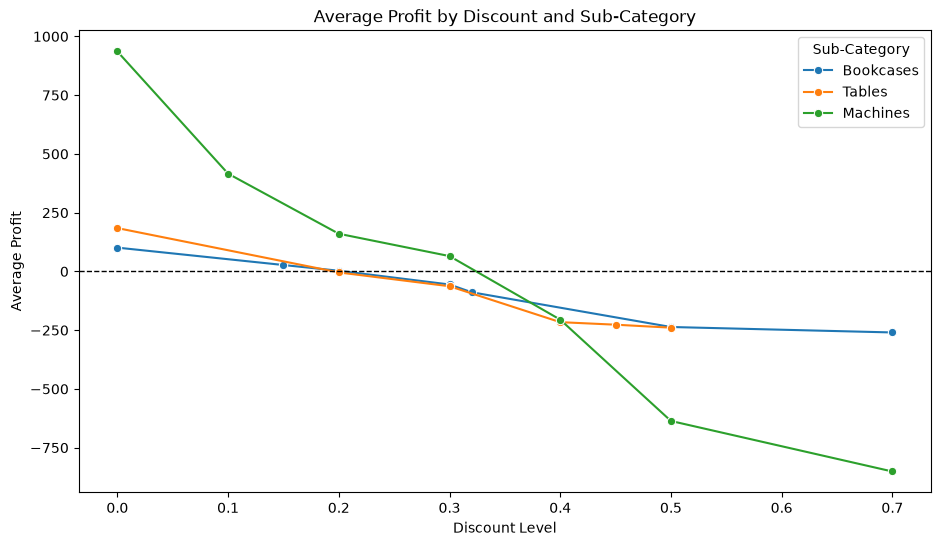

In [21]:
# Convert MultiIndex into regular columns

comparison_reset = comparison.reset_index()

# Create comparison visualization

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=comparison_reset,
    x="Discount",
    y="average_profit",
    hue="Sub-Category",
    marker="o"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Average Profit by Discount and Sub-Category")
plt.xlabel("Discount Level")
plt.ylabel("Average Profit")

plt.show()

## Key Findings - Discount and Profit Analysis

Based on the analysis of Machines, Tables, and Bookcases:

1. Average profit tends to decrease as discount levels increase.
2. Machines shows the sharpest decline in average profit.
3. Tables starts experiencing negative average profit at a lower discount level than the other two sub-categories.
4. Bookcases also shows a declining profitability trend at higher discount levels.

These findings indicate an association between discount levels
and profitability. However, they do not establish a causal
relationship.

The number of records varies across discount levels,
which should also be considered when interpreting the results.

## 10. Date Range Analysis

Explore the date range covered by the dataset
to understand its temporal coverage.

In [22]:
# Convert date columns temporarily

order_dates = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)

ship_dates = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y"
)

# Display date ranges

print("Earliest Order Date:", order_dates.min())
print("Latest Order Date:", order_dates.max())

print("Earliest Ship Date:", ship_dates.min())
print("Latest Ship Date:", ship_dates.max())

Earliest Order Date: 2014-01-03 00:00:00
Latest Order Date: 2017-12-30 00:00:00
Earliest Ship Date: 2014-01-07 00:00:00
Latest Ship Date: 2018-01-05 00:00:00


# Data Understanding Summary

## 1. Dataset Overview
- Total records: 9,994
- Total columns: 21
- Order date range: January 2014 - December 2017
- Shipping date range: January 2014 - January 2018

## 2. Data Quality
- Missing values: 0
- Exact duplicate rows: 0
- Date columns are currently stored as strings.
- Postal Code is stored as an integer and should be reviewed.

## 3. Profit Overview
- Positive profit records: 8,058
- Negative profit records: 1,871
- Zero profit records: 65

## 4. Initial Business Insights
- Profitability varies across product sub-categories.
- Machines shows a substantial decline in average profit at higher discount levels.
- Tables and Bookcases also show declining profitability.
- Higher discount levels are associated with lower average profit
  in the analyzed sub-categories.

## 5. Conclusion

The initial exploration reveals several patterns related to
product profitability and discount levels.

Further data cleaning, preprocessing, and analysis are required
before drawing more comprehensive conclusions.